# 2016年 衆議院予算委員会 発言トピック・クラスタリング

クリーニング済みの5,928発言を、SudachiPy、TF-IDF、TruncatedSVD、KMeansで政策トピック別に分類します。乱数シードは固定され、同じ入力から同じ結果を再生成できます。

In [14]:
from pathlib import Path
import os
import sys
import warnings

ROOT = Path.cwd()
if not (ROOT / 'cleaned').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(ROOT))

from clustering_2016 import (
    FIXED_K, RANDOM_STATE, apply_manual_labels, cluster_details, compare_k,
    export_results, load_input, reduce_dimensions, vectorize,
)

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
INPUT = ROOT / 'cleaned/speeches_2016.jsonl'
OUTPUT_DIR = ROOT / 'analysis/clustering_2016'
print(f'Matplotlib font: {MAC_JAPANESE_FONT} ({mac_font_paths[0]})')
RANDOM_STATE

ImportError: cannot import name 'FIXED_K' from 'clustering_2016' (/Users/tasskkiu2/kokkai/clustering_2016.py)

## 1. 入力検証

件数、会議名、発言IDの一意性、本文の欠損・空文字を検証します。条件を満たさない場合はここで停止します。

In [ ]:
df = load_input(INPUT)
validation = pd.Series({
    'rows': len(df),
    'unique_speech_ids': df['speechID'].nunique(),
    'meetings': df['nameOfMeeting'].nunique(),
    'missing_cleaned_text': int(df['speech_cleaned'].isna().sum()),
    'empty_cleaned_text': int(df['speech_cleaned'].str.strip().eq('').sum()),
    'review_flagged': int(df['review_flags'].map(bool).sum()),
})
display(validation.to_frame('value'))
display(df[['speechID', 'date', 'speaker', 'speakerPosition', 'speech_cleaned', 'review_flags']].head())

,value
rows,5928
unique_speech_ids,5928
meetings,1
missing_cleaned_text,0
empty_cleaned_text,0
review_flagged,503


,speechID,date,speaker,speakerPosition,speech_cleaned,review_flags
0,119205261X00620161214_000,2016-12-14,会議録情報,None,平成二十八年十二月十四日（水曜日） 午前十一時三十分開議 出席委員 委員長 浜田 靖一君 理...,[]
1,119205261X00520161012_000,2016-10-12,会議録情報,None,平成二十八年十月十二日（水曜日） 午前八時五十八分開議 出席委員 委員長 浜田 靖一君 理事...,[]
2,119205261X00520161012_006,2016-10-12,菅原一秀,None,おはようございます。自民党の菅原一秀です。 二十七分という時間でありますので、早速質問に入ら...,[]
3,119205261X00520161012_007,2016-10-12,松野博一,文部科学大臣,公立学校施設は、子供たちの学習、生活の場であるとともに、災害時には地域住民の避難所ともなる極...,[]
4,119205261X00520161012_008,2016-10-12,菅原一秀,None,三分の一の国の補助ですが、ぜひ、かさ上げも含めて、早急な対策をお願いしたいと思います。 次に...,[]


## 2. 日本語処理、TF-IDF、次元削減

SudachiPyで名詞・動詞・形容詞を正規形へ変換し、1〜2語gramのTF-IDFを作ります。100次元へ圧縮後、KMeans用に正規化します。

In [ ]:
source_df = df.copy()
vectorizer, tfidf, keep_mask = vectorize(source_df)
zero_vector_records = source_df.loc[~keep_mask].copy()
zero_vector_records['reason'] = 'zero_vector_after_tfidf'
df = source_df.loc[keep_mask].copy().reset_index(drop=True)
svd, reduced = reduce_dimensions(tfidf)
zero_vectors = zero_vector_records[['speechID', 'speech_cleaned', 'reason']]
print(f'TF-IDF: {tfidf.shape[0]:,} rows × {tfidf.shape[1]:,} features')
print(f'SVD explained variance: {svd.explained_variance_ratio_.sum():.1%}')
print(f'Zero vectors: {len(zero_vectors)}')
display(pd.DataFrame({'component': range(1, 11), 'explained_variance': svd.explained_variance_ratio_[:10]}))

TF-IDF: 5,928 rows × 20,000 features
SVD explained variance: 16.3%
Zero vectors: 0


,component,explained_variance
0,1,0.014067
1,2,0.002706
2,3,0.004302
3,4,0.003783
4,5,0.003551
5,6,0.003368
6,7,0.003078
7,8,0.003065
8,9,0.002740
9,10,0.002633


## 3. 10クラスタで学習

クラスタ数を `k=10` に固定して学習します。固定した2,000件標本でsilhouette scoreを確認します。

Selected k=20


,k,silhouette,inertia,smallest_cluster,largest_cluster
0,5,0.0414,"5,029.8",191,2636
1,6,0.0464,"4,960.0",192,2003
2,7,0.0514,"4,886.0",191,2254
3,8,0.0564,"4,823.7",191,1737
4,9,0.0596,"4,761.2",150,1808
5,10,0.0627,"4,704.5",176,1884
6,11,0.0647,"4,661.1",119,1453
7,12,0.0674,"4,602.9",138,1448
8,13,0.0721,"4,550.5",136,1883
9,14,0.0763,"4,499.4",118,1487


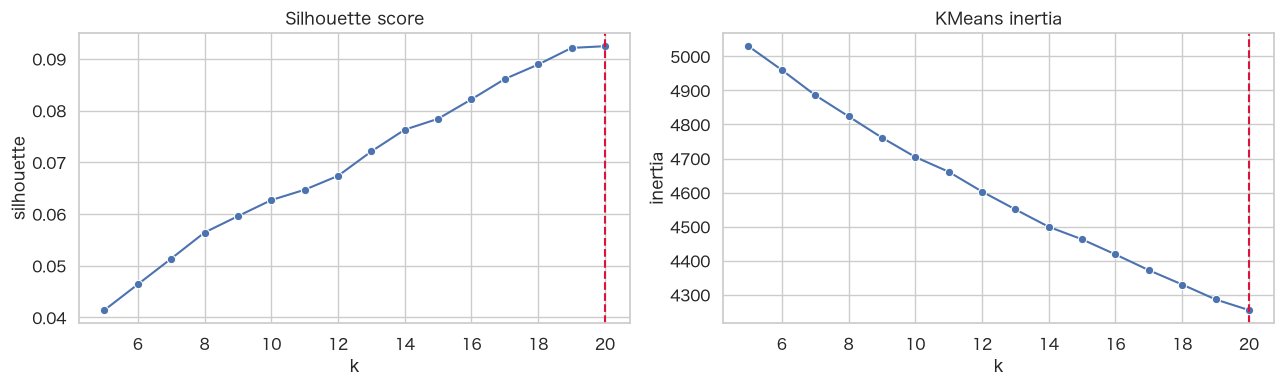

In [ ]:
scores, models = compare_k(reduced, candidates=[FIXED_K])
best_k = FIXED_K
model = models[best_k]
print(f'Fixed k={best_k}')
display(scores.style.format({'silhouette': '{:.4f}', 'inertia': '{:,.1f}'}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=scores, x='k', y='silhouette', color='steelblue', ax=axes[0])
axes[0].set_title('Silhouette score (k=10)')
sns.barplot(data=scores, x='k', y='inertia', color='darkorange', ax=axes[1])
axes[1].set_title('KMeans inertia (k=10)')
plt.tight_layout();

## 4. クラスタの解釈

上位特徴語、重心に近い代表発言、主要話者、月別分布を確認します。暫定ラベルは上位3特徴語です。

,cluster,provisional_label,count,ratio,top_terms,representative_speech_ids
0,0,日本・我が国・アメリカ,384,6.5%,日本 | 我が国 | アメリカ | 国際 | 対する | 平和 | 合意 | 世界 | 北朝鮮 | 認識 | 行う | 解決,119205261X00320161003_058 | 119005261X00620160203_050 | 119205261X00320161003_018 | 119205261X00320161003_017 | 119005261X00320160112_235
1,1,致す・調査・事実,1220,20.6%,致す | 調査 | 事実 | 検討 | 伺う | 答え | 委員会 | 先程 | 対する | 出る | 行う | 会社,119005261X00820160205_268 | 119005261X02020160516_093 | 119005261X00220160108_239 | 119005261X02020160516_090 | 119205261X00320161003_109
2,2,復興・災害・被災者,268,4.5%,復興 | 災害 | 被災者 | 被災地 | 被害 | 住宅 | 避難 | 復旧 | 支援 | 被災 | 自治体 | 再建,119205261X00420161004_020 | 119205261X00520161012_040 | 119205261X00220160930_033 | 119205261X00420161004_021 | 119005261X02020160516_004
3,3,地域・地方・取り組み,403,6.8%,地域 | 地方 | 取り組み | 支援 | 事業 | 中小企業 | 進める | 産業 | 致す | 参る | 作る | よる,119005261X01420160218_226 | 119205261X00220160930_052 | 119005261X00220160108_018 | 119005261X01620160222_014 | 119005261X00220160108_071
4,4,発言短文・致す 発言短文・間違い 発言短文,191,3.2%,発言短文 | 致す 発言短文 | 間違い 発言短文 | 間違い | 事実 発言短文 | 正す | 致す | 宜しい 発言短文 | 撤回 | とめる | 事実 | 省庁,119205261X00520161012_038 | 119005261X00920160208_321 | 119205261X00320161003_246 | 119005261X00920160208_319 | 119005261X00920160208_188
5,5,金利・マイナス・マイナス 金利,137,2.3%,金利 | マイナス | マイナス 金利 | 金融 | 日銀 | 緩和 | 総裁 | 金融 緩和 | 国債 | 政策 | 物価 | 銀行,119005261X00720160204_180 | 119005261X00720160204_191 | 119005261X01620160222_066 | 119005261X00620160203_235 | 119005261X01320160216_037
6,6,議論・政治・安倍,427,7.2%,議論 | 政治 | 安倍 | 議員 | 野党 | 国民 | 資金 | 与党 | 政治 資金 | 自民党 | 民主党 | 政党,119205261X00320161003_308 | 119005261X01720160229_168 | 119005261X01120160210_314 | 119005261X00720160204_319 | 119005261X02020160516_178
7,7,判断・番組・裁判所,178,3.0%,判断 | 番組 | 裁判所 | 裁判所 判断 | 放送 | 放送法 | 執行 | 政治的 | 日本 裁判所 | 優先 | 放送 事業者 | 見解,119005261X01720160229_132 | 119005261X01220160215_181 | 119005261X01220160215_187 | 119005261X01320160216_043 | 119005261X01620160222_233
8,8,憲法・草案・憲法改正,183,3.1%,憲法 | 草案 | 憲法改正 | 議論 | 自民党 | 審査会 | 憲法 審査会 | 国民 | 考え方 | 憲法改正 草案 | 改正 | 自衛権,119205261X00520161012_186 | 119005261X00720160204_102 | 119005261X00620160203_011 | 119205261X00320161003_072 | 119205261X00220160930_181
9,9,南スーダン・自衛隊・pko,248,4.2%,南スーダン | 自衛隊 | pko | 訓練 | 任務 | 部隊 | 戦闘 | 行為 | 武力 | 戦闘 行為 | 紛争 | 国連,119205261X00320161003_278 | 119205261X00320161003_247 | 119205261X00220160930_197 | 119005261X01720160229_209 | 119005261X00720160204_231


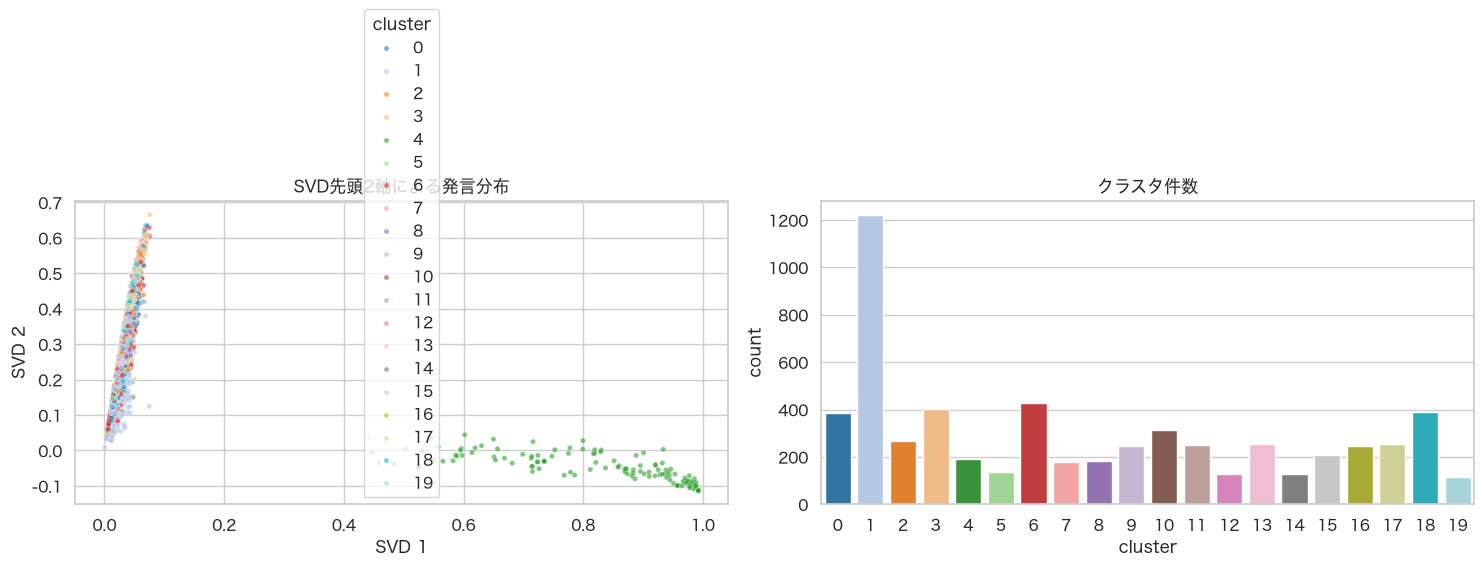

In [ ]:
assignments, summary = cluster_details(df, tfidf, reduced, vectorizer, model)
display(summary.style.format({'ratio': '{:.1%}'}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x=reduced[:, 0], y=reduced[:, 1], hue=assignments['cluster'], palette='tab20', s=14, alpha=.6, legend='full', ax=axes[0])
axes[0].set(title='SVD先頭2軸による発言分布', xlabel='SVD 1', ylabel='SVD 2')
sns.barplot(data=summary, x='cluster', y='count', hue='cluster', palette='tab20', legend=False, ax=axes[1])
axes[1].set_title('クラスタ件数')
plt.tight_layout();

In [ ]:
for cluster_id in summary['cluster']:
    row = summary.loc[summary['cluster'].eq(cluster_id)].iloc[0]
    members = assignments.loc[assignments['cluster'].eq(cluster_id)]
    representatives = members.nsmallest(5, 'centroid_distance')[['speechID', 'date', 'speaker', 'speech_cleaned', 'centroid_distance']]
    top_speakers = members['speaker'].value_counts().head(5).rename_axis('speaker').reset_index(name='count')
    print(f"\nCluster {cluster_id}: {row['provisional_label']} ({row['count']:,}件)")
    print(f"特徴語: {row['top_terms']}")
    display(top_speakers, representatives)


Cluster 0: 日本・我が国・アメリカ (384件)
特徴語: 日本 | 我が国 | アメリカ | 国際 | 対する | 平和 | 合意 | 世界 | 北朝鮮 | 認識 | 行う | 解決


,speaker,count
0,安倍晋三,69
1,岸田文雄,49
2,笠井亮,30
3,中谷元,26
4,緒方林太郎,21


,speechID,date,speaker,speech_cleaned,centroid_distance
641,119205261X00320161003_058,2016-10-03,前原誠司,金曜日の質問でも、安倍総理が稲田さんが答弁されるときに手助けをされておりますけれども、今もバ...,0.698978
4871,119005261X00620160203_050,2016-02-03,薗浦健太郎,海外からだけではなく、大臣がおっしゃったように日本企業からも非常に高い期待があると思いますの...,0.716284
602,119205261X00320161003_018,2016-10-03,前原誠司,確認をいただいたと思っております。 次に、アメリカとの関係について、この領土問題についてお話...,0.735173
601,119205261X00320161003_017,2016-10-03,安倍晋三,それはもちろん、原則を曲げるということは全く考えてもいないわけであります。何といっても日本は...,0.740180
5578,119005261X00320160112_235,2016-01-12,笠井亮,先ほど外務大臣も、意味ある対話と。そして今、建設的な、前向きなという話もあったんですが、そう...,0.741595



Cluster 1: 致す・調査・事実 (1,220件)
特徴語: 致す | 調査 | 事実 | 検討 | 伺う | 答え | 委員会 | 先程 | 対する | 出る | 行う | 会社


,speaker,count
0,安倍晋三,98
1,岩城光英,64
2,丸川珠代,51
3,麻生太郎,42
4,大西健介,41


...

,speaker,count
0,安倍晋三,119
1,石原伸晃,23
2,麻生太郎,22
3,岡田克也,12
4,柿沢未途,12


,speechID,date,speaker,speech_cleaned,centroid_distance
2481,119005261X01520160219_209,2016-02-19,真島省三,繰り返し総雇用者報酬とおっしゃっているけれども、これは会社役員の報酬まで入れた数字なんですよ...,0.661750
5690,119005261X00220160108_006,2016-01-08,新藤義孝,ちょうど三年前の十二月二十六日、第二次安倍内閣政権ができました。私も、総務大臣としてその閣僚...,0.675857
3768,119005261X00920160208_009,2016-02-08,麻生太郎,まずは何がといって、やはりデフレというものは、これはデフレ好況もありますので、デフレ不況から...,0.676902
3286,119005261X01220160215_341,2016-02-15,安倍晋三,経済の状況についてでありますが、先ほど申し上げたとおりでありまして、この二十年間の最大の問題...,0.688175
1558,119005261X01820160301_073,2016-03-01,福島伸享,せっかく私は、民主党政権が悪かった、アベノミクスは成功したという二元論から脱して冷静に質問し...,0.688306



Cluster 19: 定数・答申・削減 (117件)
特徴語: 定数 | 答申 | 削減 | 定数 削減 | アダムズ | アダムズ 方式 | 選挙 | 方式 | 議論 | 自民党 | 結論 | 尊重


,speaker,count
0,安倍晋三,49
1,岡田克也,14
2,塩川鉄也,11
3,高井崇志,7
4,松野頼久,6


,speechID,date,speaker,speech_cleaned,centroid_distance
4819,119005261X00720160204_321,2016-02-04,安倍晋三,我が党の中において、まさに今、議論をスタートしたところでございます。 いわば、要請としては、...,0.440910
2402,119005261X01520160219_126,2016-02-19,野田佳彦,いやあ、びっくりぽんですね。本当に驚きますね。これでは前向きな議論はできないですよ。 随分過...,0.455190
1799,119005261X01720160229_181,2016-02-29,安倍晋三,私は第三者委員会の答申を尊重すると言っているわけでありますし、私が申し上げていることは基本的...,0.465294
3167,119005261X01220160215_217,2016-02-15,高井崇志,岡山から参りました、維新の党の高井でございます。 総理、今の質疑を後ろで聞いていましたけれど...,0.483369
2399,119005261X01520160219_123,2016-02-19,安倍晋三,三年ぶりにこうして元気な野田総理とお目にかかれて、私も大変うれしく思います。 そこで、二〇一...,0.502586


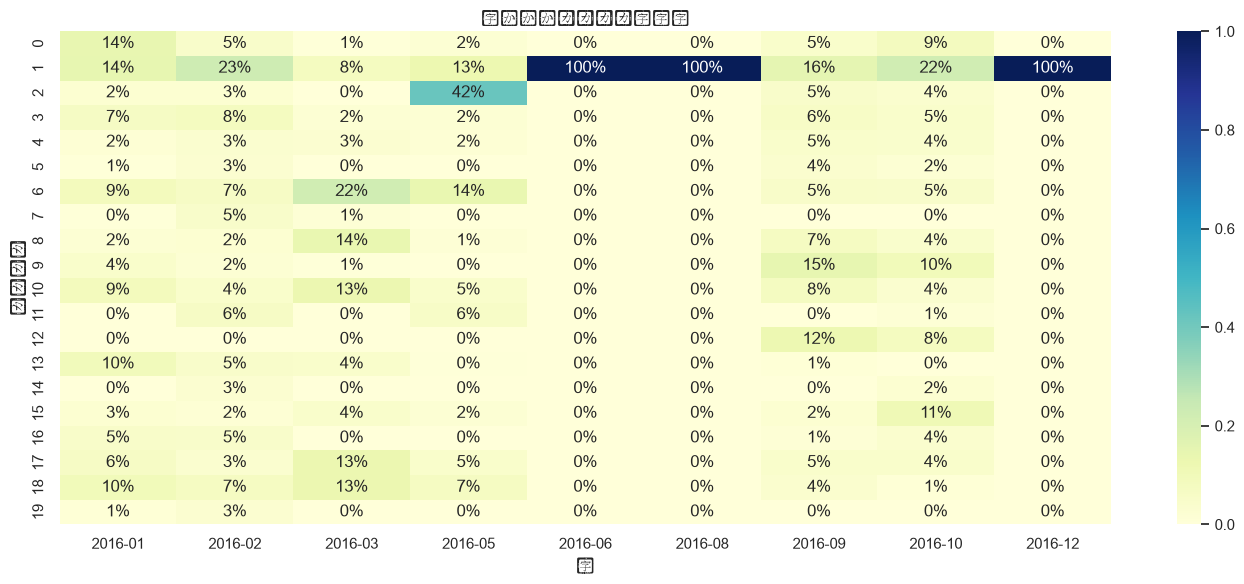

In [ ]:
monthly = pd.crosstab(assignments['month'], assignments['cluster'], normalize='index')
plt.figure(figsize=(14, 6))
sns.heatmap(monthly.T, cmap='YlGnBu', annot=True, fmt='.0%')
plt.title('月ごとのクラスタ構成比')
plt.xlabel('月')
plt.ylabel('クラスタ')
plt.tight_layout();

## 5. 人手によるラベル調整

代表発言を確認し、必要なクラスタだけ辞書へ名称を追加してください。空のまま実行すると暫定ラベルを使用します。

In [ ]:
MANUAL_CLUSTER_LABELS = {
    # 0: '社会保障・医療',
    # 1: '外交・安全保障',
}
assignments, summary = apply_manual_labels(assignments, summary, MANUAL_CLUSTER_LABELS)
display(summary[['cluster', 'cluster_label', 'count', 'ratio', 'top_terms']].style.format({'ratio': '{:.1%}'}))

,cluster,cluster_label,count,ratio,top_terms
0,0,日本・我が国・アメリカ,384,6.5%,日本 | 我が国 | アメリカ | 国際 | 対する | 平和 | 合意 | 世界 | 北朝鮮 | 認識 | 行う | 解決
1,1,致す・調査・事実,1220,20.6%,致す | 調査 | 事実 | 検討 | 伺う | 答え | 委員会 | 先程 | 対する | 出る | 行う | 会社
2,2,復興・災害・被災者,268,4.5%,復興 | 災害 | 被災者 | 被災地 | 被害 | 住宅 | 避難 | 復旧 | 支援 | 被災 | 自治体 | 再建
3,3,地域・地方・取り組み,403,6.8%,地域 | 地方 | 取り組み | 支援 | 事業 | 中小企業 | 進める | 産業 | 致す | 参る | 作る | よる
4,4,発言短文・致す 発言短文・間違い 発言短文,191,3.2%,発言短文 | 致す 発言短文 | 間違い 発言短文 | 間違い | 事実 発言短文 | 正す | 致す | 宜しい 発言短文 | 撤回 | とめる | 事実 | 省庁
5,5,金利・マイナス・マイナス 金利,137,2.3%,金利 | マイナス | マイナス 金利 | 金融 | 日銀 | 緩和 | 総裁 | 金融 緩和 | 国債 | 政策 | 物価 | 銀行
6,6,議論・政治・安倍,427,7.2%,議論 | 政治 | 安倍 | 議員 | 野党 | 国民 | 資金 | 与党 | 政治 資金 | 自民党 | 民主党 | 政党
7,7,判断・番組・裁判所,178,3.0%,判断 | 番組 | 裁判所 | 裁判所 判断 | 放送 | 放送法 | 執行 | 政治的 | 日本 裁判所 | 優先 | 放送 事業者 | 見解
8,8,憲法・草案・憲法改正,183,3.1%,憲法 | 草案 | 憲法改正 | 議論 | 自民党 | 審査会 | 憲法 審査会 | 国民 | 考え方 | 憲法改正 草案 | 改正 | 自衛権
9,9,南スーダン・自衛隊・pko,248,4.2%,南スーダン | 自衛隊 | pko | 訓練 | 任務 | 部隊 | 戦闘 | 行為 | 武力 | 戦闘 行為 | 紛争 | 国連


## 6. CSV出力と最終検証

UTF-8 BOM付きで発言別結果とクラスタ要約を保存します。

In [ ]:
assert len(assignments) == len(df)
assert assignments['cluster'].notna().all()
assert set(assignments['cluster']) == set(range(best_k))
assert summary['count'].sum() == len(df)
assert best_k == 10
assert len(scores) == 1

export_results(assignments, summary, OUTPUT_DIR)
clusters_path = OUTPUT_DIR / 'speech_clusters.csv'
summary_path = OUTPUT_DIR / 'cluster_summary.csv'
assert len(pd.read_csv(clusters_path)) == len(df)
assert len(pd.read_csv(summary_path)) == best_k
print(f'発言別結果: {clusters_path}')
print(f'クラスタ要約: {summary_path}')
print(f'検証完了: {len(assignments):,}件、{best_k}クラスタ')